In [ ]:
import os

os.chdir('/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC')
from reproject.mosaicking import find_optimal_celestial_wcs, reproject_and_coadd
import scripts.phot_toolkits as phot_tk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits

from astropy.stats import knuth_bin_width
from pathlib import Path
import csv
%load_ext autoreload
%autoreload 2




**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
The following task in the stsci.skypac package can be run with TEAL:
                                    skymatch                                    


(-5.0, 5.0)

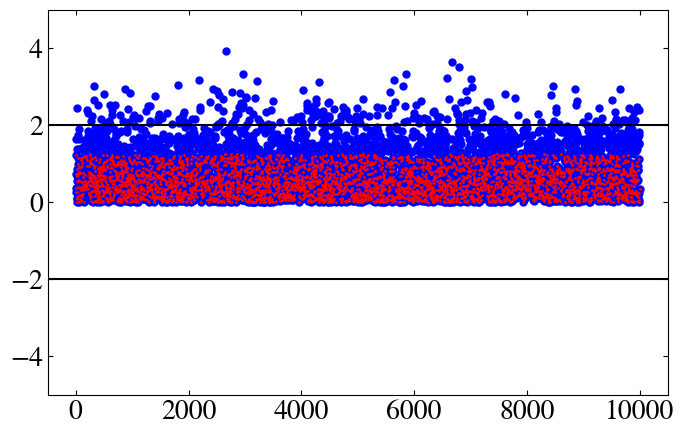

In [ ]:
from astropy.stats import sigma_clip
from numpy.random import randn
x = np.linspace(0,10000, 10000)
randvar = randn(10000)

mask            = ((randvar > 0) & np.isfinite(randvar))
randvar[~mask]  = np.nan
filtered_data   = sigma_clip(randvar, sigma=2, maxiters=5)
plt.scatter(x, randvar, s = 25, c='blue')
plt.scatter(x, filtered_data, s=1, c='red')
plt.axhline(2, ls='-', c='black')
plt.axhline(-2, ls='-',c='k')
plt.ylim(-5,5)


(-5.0, 5.0)

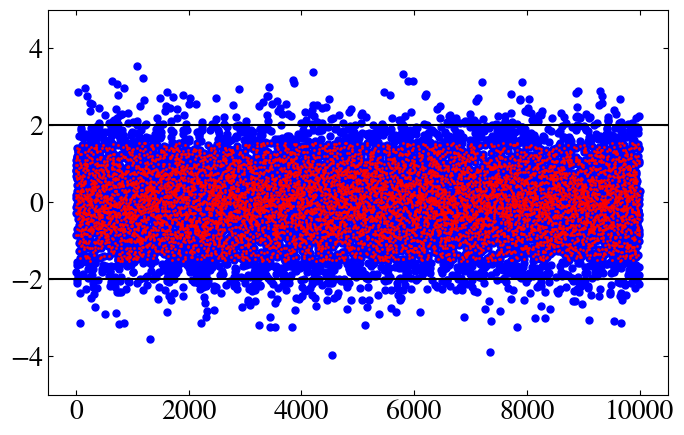

In [2]:
JWST_files = phot_tk.Pipeline_level_2_data(working_directory = "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST")

Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


Running for F115W...
    (3) Running starbug
Launching Starbug environment in its venv...
launching starbug

                   *          *  __  *  __   - * --   - 
 STARBUGII               *      / ___ /    \   --  -      - 
 ---------                 *___---.    .___/  -   --   -
 JWST photometry in       ./=== \  \.     \      * 
 complex crowded fields   | (O)  |  |     |           *
                           \._._/ ./    _(\)   *   
 conor.nally@ed.ac.uk     /   ~--\ ----~   \      *
                        ---      ___       ---      
 > https://starbug2.readthedocs.io/en/latest/

-> showing starbug stdout for "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST/jw01227002003_02103_00003_nrca2/jw01227002003_02103_00003_nrca2_cal_1overf_jhat.fits"
loaded: "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST/jw01227002003_02103_00003_nrca2/jw01227002003_02103_00003_nrca2_cal_1overf_jhat.fits"
-> using image HDU: 1 (SCI)
-> photometric band: F115W

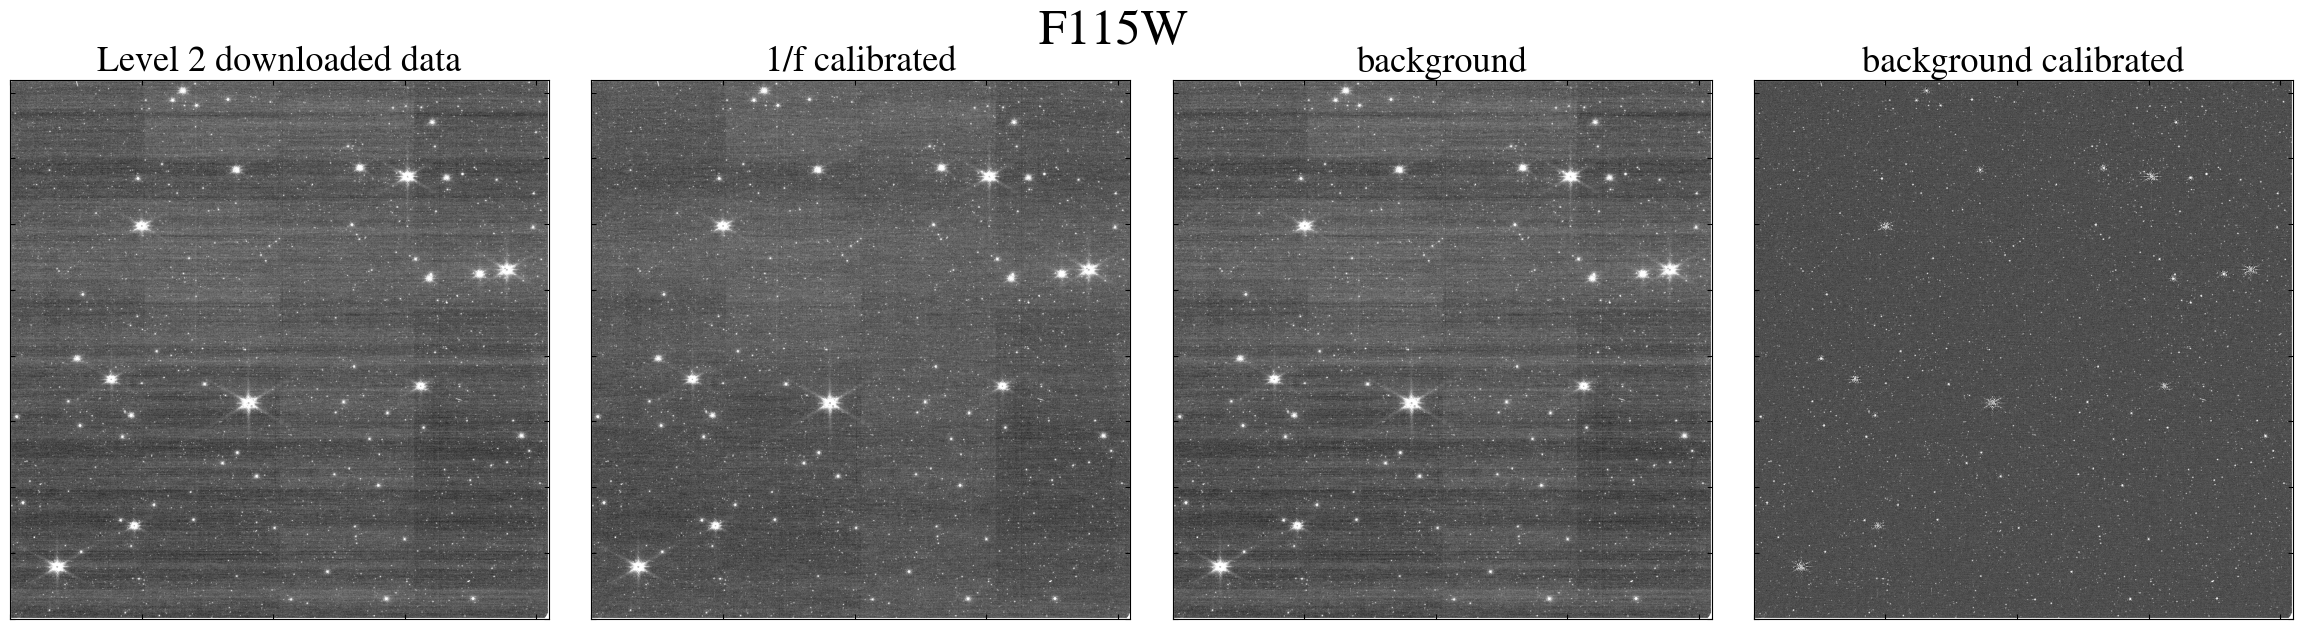

----Pipeline-----
JWST pipeline version             : 2.0.1
Calibration Reference Data System : 13.1.13
CRDS context map                  : jwst_1535.pmap
Read-out pattern                  : BRIGHT2
Number of read-out groups         : 2
----Completed----


In [3]:
JWST_files.run_pipeline_single( IMAGE_INDEX         = 81,
                                detection_sigma     = 2.0,
                                overwrite_always_run= False,
                                save                = True,)


In [ ]:
JWST_files.starbug2_aperture_photometry_on_mosaic(  mosaic_path             = '/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_3/mosaic_F115W_short_exposure.fits',
                                                    filter                  = 'F115W',
                                                    mode                    = "short",
                                                    remove_background       = True,
                                                    toggle_sb_output_txt    = True,
                                                    overwrite_always_run    = True,
                                                )


Launching Starbug environment in its venv...
